In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd

#path
from pathlib import Path
import os.path

#plotting
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

#sklearn matrics
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn import metrics

#tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models
from keras.models import Sequential,load_model,Model
from keras.layers import Conv2D,MaxPool2D,AveragePooling2D,Dense,Flatten,ZeroPadding2D,BatchNormalization,Activation,Add,Input,Dropout,GlobalAveragePooling2D
from keras.optimizers import SGD
from keras.initializers import glorot_uniform

#time
from time import perf_counter

In [ ]:
image_dir = Path('/content/drive/MyDrive/ chest-x-ray-/Chest_Radiography_Database (1)')
filepaths = list(image_dir.glob(r'**/*/*'))
labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepaths))

In [ ]:
filepaths = pd.Series(filepaths, name='Filepath').astype(str)
labels = pd.Series(labels, name='Label')

# Concatenate filepaths and labels
image_df = pd.concat([filepaths, labels], axis=1)

# Shuffle the DataFrame and reset index
image_df = image_df.sample(frac=1).reset_index(drop = True)

# Show the result
image_df.head(4)

,Filepath,Label
0,/content/drive/MyDrive/ chest-x-ray-/Chest_Rad...,Normal (1)
1,/content/drive/MyDrive/ chest-x-ray-/Chest_Rad...,Viral Pneumonia (1)
2,/content/drive/MyDrive/ chest-x-ray-/Chest_Rad...,Viral Pneumonia (1)
3,/content/drive/MyDrive/ chest-x-ray-/Chest_Rad...,Tuberculosis (1)


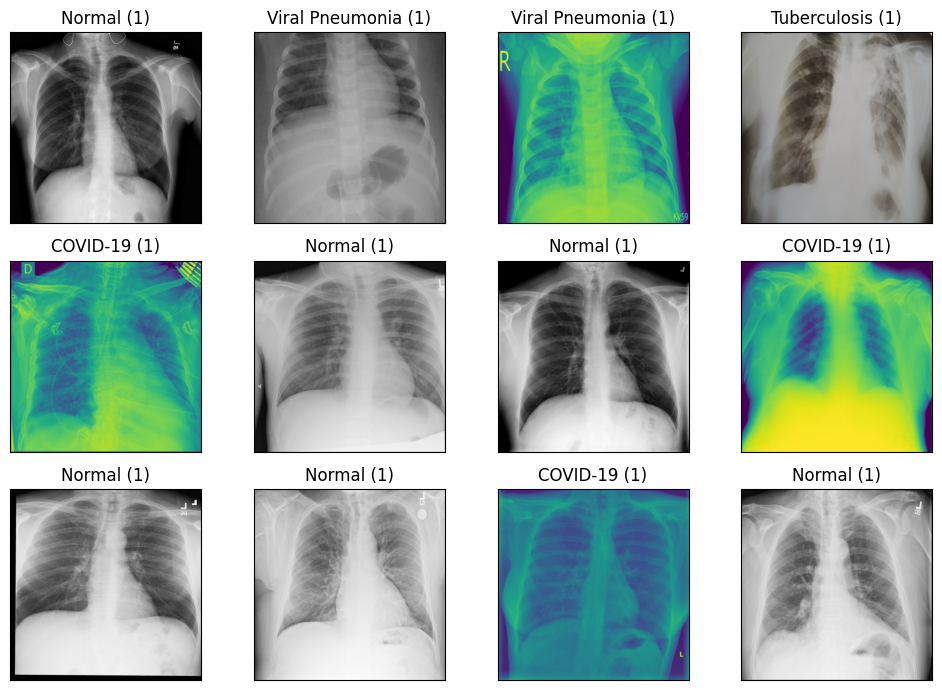

In [ ]:
# Display some pictures of the dataset with their labels
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(10, 7),
                        subplot_kw={'xticks': [], 'yticks': []})

for i, ax in enumerate(axes.flat):

    ax.imshow(plt.imread(image_df.Filepath[i]))
    ax.set_title(image_df.Label[i])
plt.tight_layout()
plt.show()

In [ ]:
vc = image_df['Label'].value_counts()
print(vc)

Label
COVID-19 (1)           3616
Normal (1)             3500
Viral Pneumonia (1)    1345
Tuberculosis (1)        700
Name: count, dtype: int64


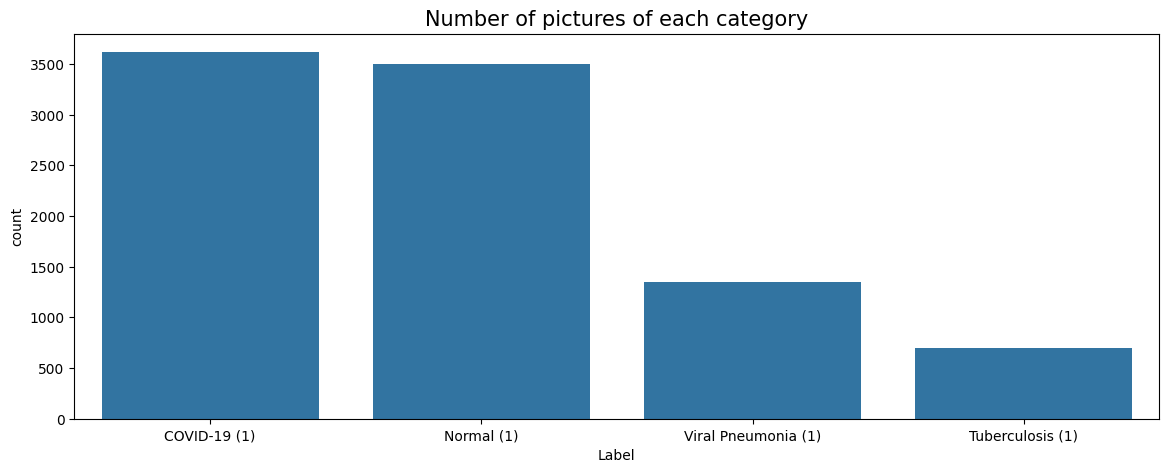

In [ ]:
# Display the number of pictures of each category
vc = image_df['Label'].value_counts()
plt.figure(figsize=(14,5))
sns.barplot(x = vc.index, y = vc)
plt.title("Number of pictures of each category", fontsize = 15)
plt.show()

In [ ]:
def create_gen():
    # Load the Images with a generator and Data Augmentation
    train_generator = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.1
    )

    test_generator = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
    )

    train_images = train_generator.flow_from_dataframe(
        dataframe=train_df,
        x_col='Filepath',
        y_col='Label',
        target_size=(224, 224),
        color_mode='rgb',
        class_mode='categorical',
        batch_size=16,
        shuffle=True,
        subset='training'
    )

    val_images = train_generator.flow_from_dataframe(
        dataframe=train_df,
        x_col='Filepath',
        y_col='Label',
        target_size=(224, 224),
        color_mode='rgb',
        class_mode='categorical',
        batch_size=16,
        shuffle=True,
        subset='validation'
    )

    test_images = test_generator.flow_from_dataframe(
        dataframe=test_df,
        x_col='Filepath',
        y_col='Label',
        target_size=(224, 224),
        color_mode='rgb',
        class_mode='categorical',
        batch_size=16,
        shuffle=False
    )

    return train_generator,test_generator,train_images,val_images,test_images

In [ ]:
def get_model(model):
# Load the pretained model
    kwargs =    {'input_shape':(224, 224, 3),
                'include_top':False,
                'weights':'imagenet',
                'pooling':'avg'}

    pretrained_model = model(**kwargs)
    pretrained_model.trainable = False

    inputs = pretrained_model.input

    x = tf.keras.layers.Dense(256, activation='relu')(pretrained_model.output)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(4, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


In [ ]:
# Separate in train and test data
train_df, test_df = train_test_split(image_df, train_size=0.8, shuffle=True, random_state=1)

Found 6596 validated image filenames belonging to 4 classes.
Found 732 validated image filenames belonging to 4 classes.
Found 1833 validated image filenames belonging to 4 classes.






74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
DenseNet201 Model Training Started ===>>>
Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1671s 4s/step - accuracy: 0.8307 - loss: 0.4340 - val_accuracy: 0.8347 - val_loss: 0.3969
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 71s 171ms/step - accuracy: 0.9186 - loss: 0.2154 - val_accuracy: 0.9699 - val_loss: 0.0880
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 72s 174ms/step - accuracy: 0.9413 - loss: 0.1691 - val_accuracy: 0.9631 - val_loss: 0.0874
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 72s 175ms/step - accuracy: 0.9513 - loss: 0.1454 - val_accuracy: 0.9672 - val_loss: 0.1091
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 72s 175ms/step - accuracy: 0.9457 - loss: 0.1535 - val_accuracy: 0.9754 - val_loss: 0.0803
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 79s 192ms/step - accuracy

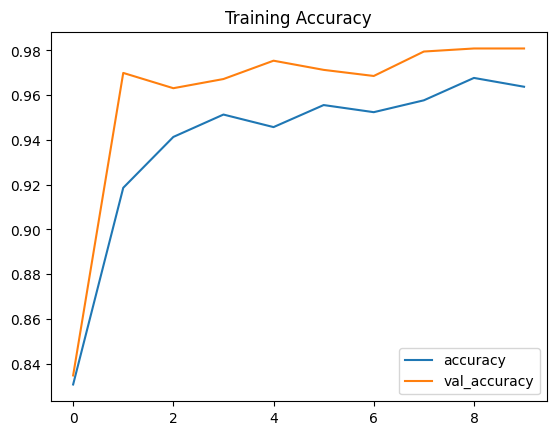

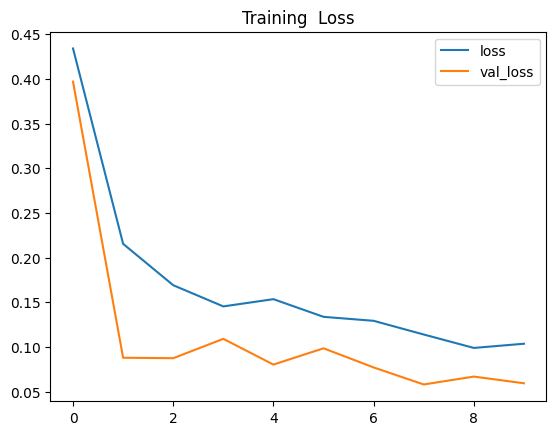



Accuracy on the test set: 97.76%
115/115 ━━━━━━━━━━━━━━━━━━━━ 72s 388ms/step
Accuracy: 0.97763
Precision: 0.97777
Recall: 0.97763
F1 Score: 0.97764
                     precision    recall  f1-score   support

       COVID-19 (1)       0.98      0.97      0.97       724
         Normal (1)       0.98      0.99      0.98       707
   Tuberculosis (1)       0.94      0.99      0.96       138
Viral Pneumonia (1)       0.99      0.98      0.98       264

           accuracy                           0.98      1833
          macro avg       0.97      0.98      0.98      1833
       weighted avg       0.98      0.98      0.98      1833

DenseNet201 Confusion Matrix: 




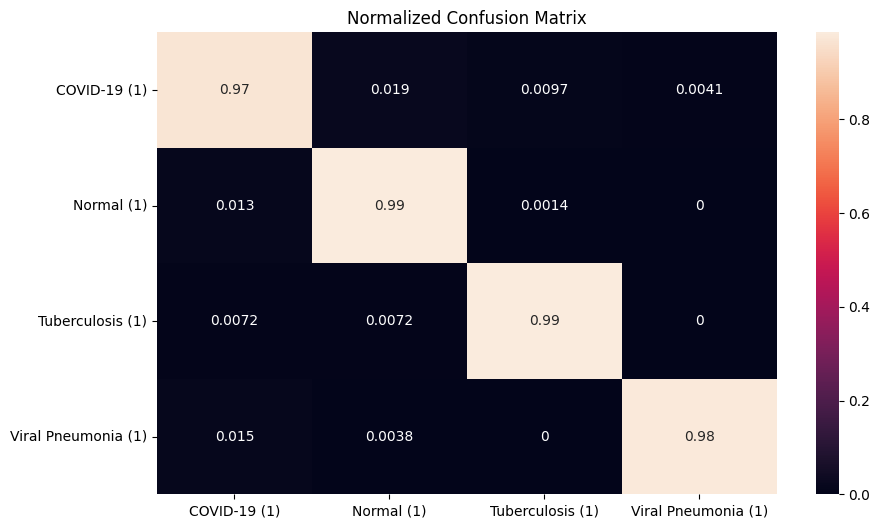

Performance: 

Rec=    97.98186023991713
Spe=    99.99889839532746
Pre=    97.99321477054615
FPR=    0.0011016046725343199
FNR=    2.0181397600828683
NPV=    99.99889839558466
FDR=    2.0067852294538593




219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
InceptionResNetV2 Model Training Started ===>>>
Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 140s 261ms/step - accuracy: 0.6891 - loss: 0.7647 - val_accuracy: 0.8443 - val_loss: 0.4270
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 90s 173ms/step - accuracy: 0.7843 - loss: 0.5452 - val_accuracy: 0.8661 - val_loss: 0.3692
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 73s 178ms/step - accuracy: 0.7979 - loss: 0.4961 - val_accuracy: 0.8511 - val_loss: 0.4102
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 76s 183ms/step - accuracy: 0.8026 - loss: 0.4789 - val_accuracy: 0.8770 - val_loss: 0.3363
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 73s 177ms/step - accuracy: 0.8029 - loss: 0.4679 - val_accuracy: 0.8893 - val_loss: 0.3706
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━

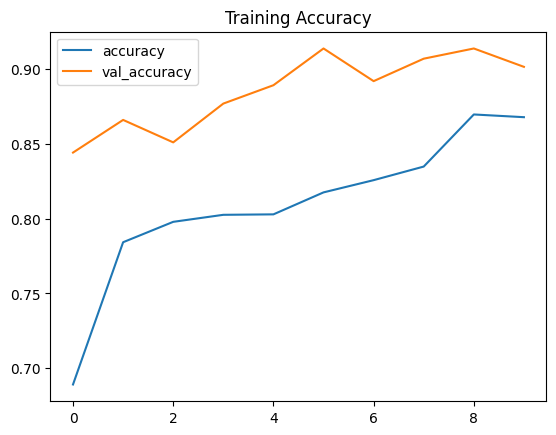

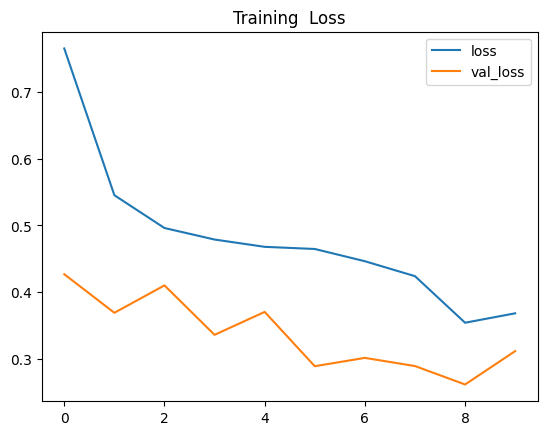



Accuracy on the test set: 91.00%
115/115 ━━━━━━━━━━━━━━━━━━━━ 45s 274ms/step
Accuracy: 0.90998
Precision: 0.9116
Recall: 0.90998
F1 Score: 0.90956
                     precision    recall  f1-score   support

       COVID-19 (1)       0.89      0.90      0.90       724
         Normal (1)       0.89      0.92      0.91       707
   Tuberculosis (1)       0.99      0.76      0.86       138
Viral Pneumonia (1)       0.97      0.98      0.97       264

           accuracy                           0.91      1833
          macro avg       0.94      0.89      0.91      1833
       weighted avg       0.91      0.91      0.91      1833

InceptionResNetV2 Confusion Matrix: 




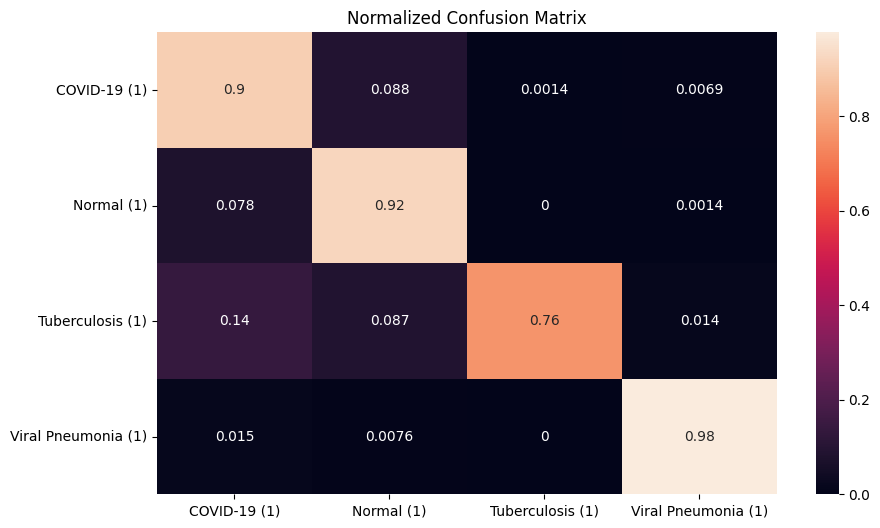

Performance: 

Rec=    89.05623222062779
Spe=    99.99402632763135
Pre=    90.15632072758847
FPR=    0.005973672368652959
FNR=    10.943767779372216
NPV=    99.99402659338097
FDR=    9.843679272411535




83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Xception Model Training Started ===>>>
Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 128s 253ms/step - accuracy: 0.7843 - loss: 0.5400 - val_accuracy: 0.8607 - val_loss: 0.3405
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 66s 161ms/step - accuracy: 0.8581 - loss: 0.3754 - val_accuracy: 0.8811 - val_loss: 0.2791
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 69s 166ms/step - accuracy: 0.8843 - loss: 0.3068 - val_accuracy: 0.8770 - val_loss: 0.2661
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 69s 167ms/step - accuracy: 0.8878 - loss: 0.2922 - val_accuracy: 0.9057 - val_loss: 0.2229
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 68s 165ms/step - accuracy: 0.8990 - loss: 0.2684 - val_accuracy: 0.9290 - val_loss: 0.1931
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 68s 165ms

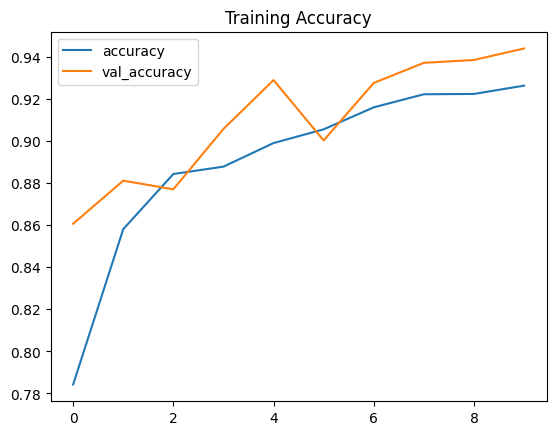

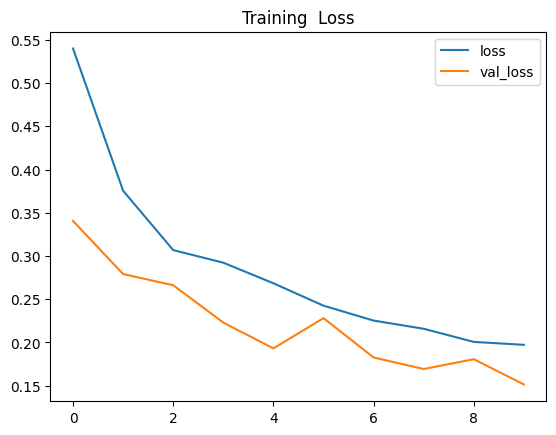



Accuracy on the test set: 92.69%
115/115 ━━━━━━━━━━━━━━━━━━━━ 27s 184ms/step
Accuracy: 0.9269
Precision: 0.92752
Recall: 0.9269
F1 Score: 0.92667
                     precision    recall  f1-score   support

       COVID-19 (1)       0.94      0.89      0.92       724
         Normal (1)       0.90      0.94      0.92       707
   Tuberculosis (1)       0.93      0.91      0.92       138
Viral Pneumonia (1)       0.95      0.99      0.97       264

           accuracy                           0.93      1833
          macro avg       0.93      0.93      0.93      1833
       weighted avg       0.93      0.93      0.93      1833

Xception Confusion Matrix: 




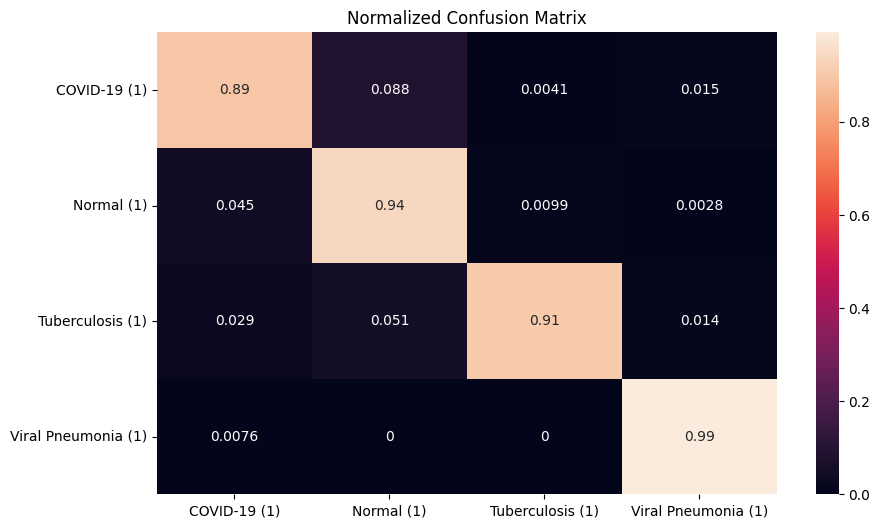

Performance: 

Rec=    93.31237559516563
Spe=    99.99634954999736
Pre=    93.50814551434577
FPR=    0.003650450002638845
FNR=    6.687624404834361
NPV=    99.99634959058115
FDR=    6.491854485654244




58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
VGG16 Model Training Started ===>>>
Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 99s 214ms/step - accuracy: 0.7229 - loss: 0.6763 - val_accuracy: 0.8757 - val_loss: 0.3423
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 70s 170ms/step - accuracy: 0.8469 - loss: 0.3912 - val_accuracy: 0.8934 - val_loss: 0.2914
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 70s 169ms/step - accuracy: 0.8780 - loss: 0.3178 - val_accuracy: 0.9194 - val_loss: 0.2331
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 69s 168ms/step - accuracy: 0.8918 - loss: 0.2823 - val_accuracy: 0.9303 - val_loss: 0.2157
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 70s 168ms/step - accuracy: 0.8975 - loss: 0.2643 - val_accuracy: 0.9262 - val_loss: 0.2062
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 70s 170ms/step

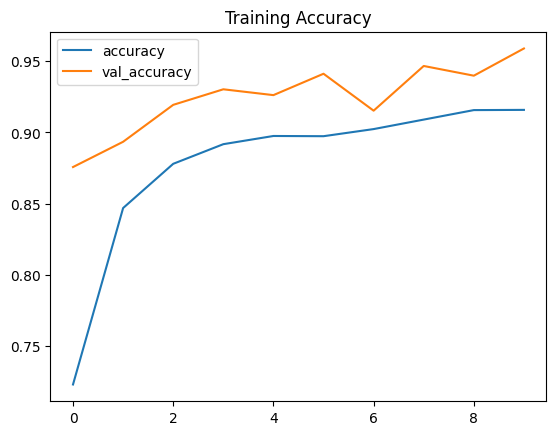

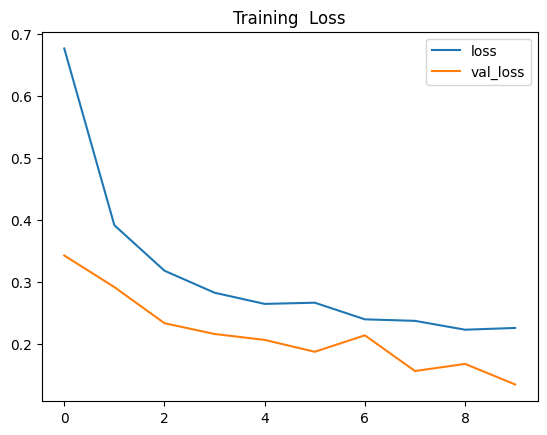



Accuracy on the test set: 94.76%
115/115 ━━━━━━━━━━━━━━━━━━━━ 19s 158ms/step
Accuracy: 0.94763
Precision: 0.94769
Recall: 0.94763
F1 Score: 0.94759
                     precision    recall  f1-score   support

       COVID-19 (1)       0.93      0.95      0.94       724
         Normal (1)       0.95      0.94      0.95       707
   Tuberculosis (1)       0.94      0.90      0.92       138
Viral Pneumonia (1)       0.98      0.98      0.98       264

           accuracy                           0.95      1833
          macro avg       0.95      0.94      0.95      1833
       weighted avg       0.95      0.95      0.95      1833

VGG16 Confusion Matrix: 




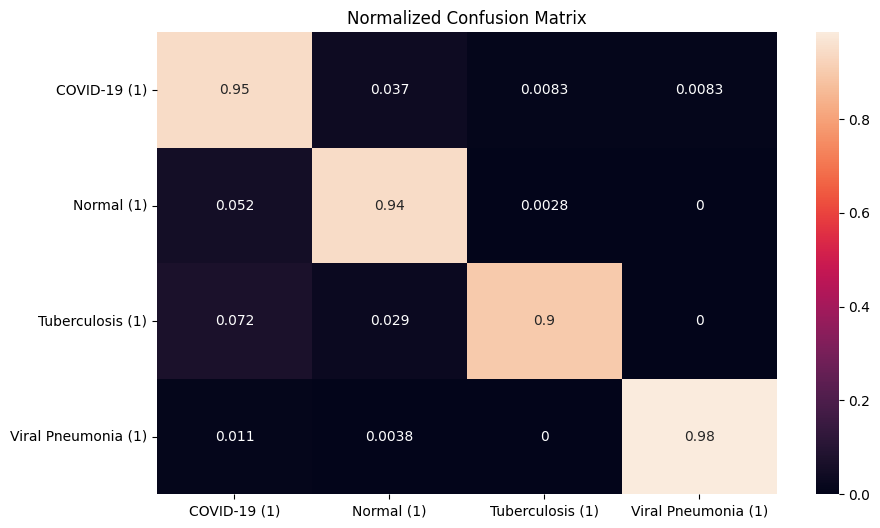

Performance: 

Rec=    94.35922867620484
Spe=    99.99692097635165
Pre=    94.61475285902135
FPR=    0.0030790236483598066
FNR=    5.640771323795157
NPV=    99.99692100624017
FDR=    5.385247140978659




94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
ResNet50 Model Training Started ===>>>
Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 95s 198ms/step - accuracy: 0.4610 - loss: 1.1757 - val_accuracy: 0.5492 - val_loss: 1.0714
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 71s 173ms/step - accuracy: 0.5112 - loss: 1.0783 - val_accuracy: 0.4822 - val_loss: 1.1319
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 67s 161ms/step - accuracy: 0.4926 - loss: 1.0882 - val_accuracy: 0.5109 - val_loss: 1.0650
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 69s 167ms/step - accuracy: 0.4815 - loss: 1.0836 - val_accuracy: 0.6066 - val_loss: 0.9396
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 68s 164ms/step - accuracy: 0.4745 - loss: 1.1151 - val_accuracy: 0.4809 - val_loss: 1.0962
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 68s 164ms/

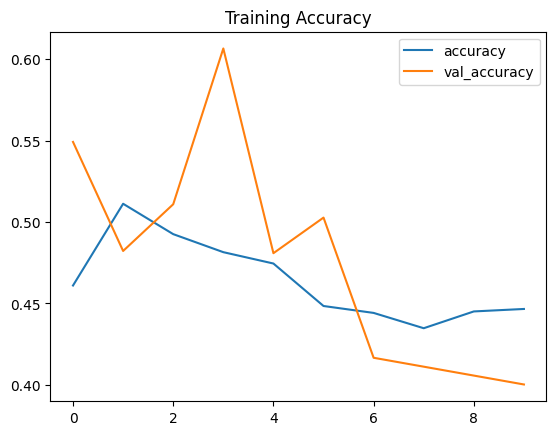

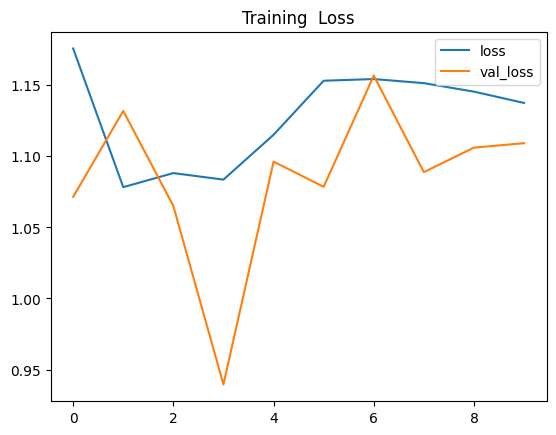



Accuracy on the test set: 39.44%
115/115 ━━━━━━━━━━━━━━━━━━━━ 26s 192ms/step
Accuracy: 0.39444
Precision: 0.48593
Recall: 0.39444
F1 Score: 0.23417
                     precision    recall  f1-score   support

       COVID-19 (1)       0.85      0.02      0.05       724
         Normal (1)       0.39      1.00      0.56       707
   Tuberculosis (1)       0.00      0.00      0.00       138
Viral Pneumonia (1)       0.00      0.00      0.00       264

           accuracy                           0.39      1833
          macro avg       0.31      0.26      0.15      1833
       weighted avg       0.49      0.39      0.23      1833

ResNet50 Confusion Matrix: 




/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

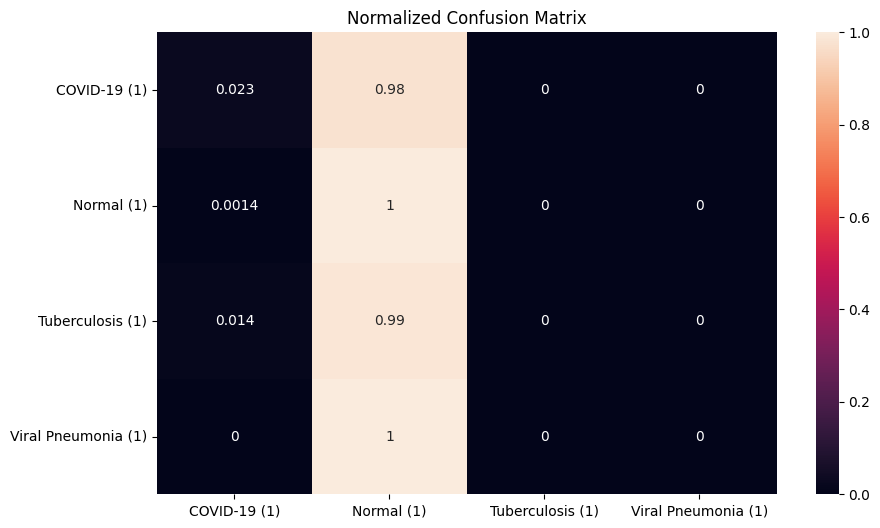

Performance: 

Rec=    25.551655895660595
Spe=    99.95936225758497
Pre=    nan
FPR=    0.04063774241503242
FNR=    74.4483441043394
NPV=    99.95938409968547
FDR=    nan




/tmp/ipykernel_1999/362870023.py:106: RuntimeWarning: invalid value encountered in divide
  PPV = TP/(TP+FP)
/tmp/ipykernel_1999/362870023.py:114: RuntimeWarning: invalid value encountered in divide
  FDR = FP/(TP+FP)


In [ ]:
 # Dictionary with the models

models = {
    "DenseNet201": {"model":tf.keras.applications.DenseNet201, "perf":0},
    "InceptionResNetV2": {"model":tf.keras.applications.InceptionResNetV2, "perf":0},
    "Xception": {"model":tf.keras.applications.Xception, "perf":0},
    "VGG16": {"model":tf.keras.applications.VGG16, "perf":0},
    "ResNet50": {"model":tf.keras.applications.ResNet50, "perf":0},
}

# Create the generators
train_generator,test_generator,train_images,val_images,test_images = create_gen()
print('\n')
print('\n')

# Fit the models
for name, model in models.items():
    print('\n')

    # Get the model
    m = get_model(model['model'])
    models[name]['model'] = m


    print(f"{name:2} Model Training Started ===>>>")


    start = perf_counter()

    # Fit the model
    history = m.fit(train_images,validation_data=val_images,epochs=10,verbose=1)

    # Save the duration, the train_accuracy and the val_accuracy
    duration = perf_counter() - start
    duration = round(duration,2)
    models[name]['perf'] = duration
    print(f"{name:2} trained in {duration} sec")

    val_acc = history.history['val_accuracy']
    models[name]['val_acc'] = [round(v,4) for v in val_acc]

    train_acc = history.history['accuracy']
    models[name]['train_accuracy'] = [round(v,4) for v in train_acc]

    results = m.evaluate(test_images, verbose=0)
    res=results[1]
    models[name]['test_accuracy'] = [round(res,4)]

    #ploting training acc loss
    print(f"{name:2} Train Accuracy and Loss Plot: \n")

    pd.DataFrame(history.history)[['accuracy','val_accuracy']].plot()
    plt.title("Training Accuracy")
    plt.show()
    pd.DataFrame(history.history)[['loss','val_loss']].plot()
    plt.title("Training  Loss")
    plt.show()

    print("\n\nAccuracy on the test set: {:.2f}%".format(results[1] * 100))


    from sklearn.metrics import confusion_matrix
    import seaborn as sns

    pred = m.predict(test_images)
    pred = np.argmax(pred,axis=1)

    # Map the label
    labels = (train_images.class_indices)
    labels = dict((v,k) for k,v in labels.items())
    pred = [labels[k] for k in pred]
    y_test = list(test_df.Label)

    print('Accuracy:', np.round(metrics.accuracy_score(y_test, pred),5))
    print('Precision:', np.round(metrics.precision_score(y_test, pred, average='weighted'),5))
    print('Recall:', np.round(metrics.recall_score(y_test,pred, average='weighted'),5))
    print('F1 Score:', np.round(metrics.f1_score(y_test, pred, average='weighted'),5))
    print(classification_report(y_test, pred))


    from sklearn.metrics import mean_absolute_error
    from sklearn.metrics import mean_squared_error
    import math
    from numpy import mean


    print(f"{name:2} Confusion Matrix: \n\n")
    cf_matrix = confusion_matrix(y_test, pred, normalize='true')
    plt.figure(figsize = (10,6))
    sns.heatmap(cf_matrix, annot=True, xticklabels = sorted(set(y_test)), yticklabels = sorted(set(y_test)))
    plt.title('Normalized Confusion Matrix')
    plt.show()

    confusion_matrix=cf_matrix

    FP = confusion_matrix.sum(axis=0) - np.diag(confusion_matrix)
    FN = confusion_matrix.sum(axis=1) - np.diag(confusion_matrix)
    TP = np.diag(confusion_matrix)
    TN = len(y_test) - (FP + FN + TP)

    # Sensitivity, hit rate, recall, or true positive rate
    TPR = TP/(TP+FN)
    # Specificity or true negative rate
    TNR = TN/(TN+FP)
    # Precision or positive predictive value
    PPV = TP/(TP+FP)
    # Negative predictive value
    NPV = TN/(TN+FN)
    # Fall out or false positive rate
    FPR = FP/(FP+TN)
    # False negative rate
    FNR = FN/(TP+FN)
    # False discovery rate
    FDR = FP/(TP+FP)
    print("Performance: \n")
    print("Rec=   ",mean(TPR)*100)
    print("Spe=   ",mean(TNR)*100)
    print("Pre=   ",mean(PPV)*100)
    print("FPR=   ",mean(FPR)*100)
    print("FNR=   ",mean(FNR)*100)
    print("NPV=   ",mean(NPV)*100)
    print("FDR=   ",mean(FDR)*100)
    print("\n")

In [ ]:
# Install required packages
!pip install -q lime scikit-image

Generating SHAP plots for DenseNet201...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)
/tmp/ipykernel_1999/1386099334.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


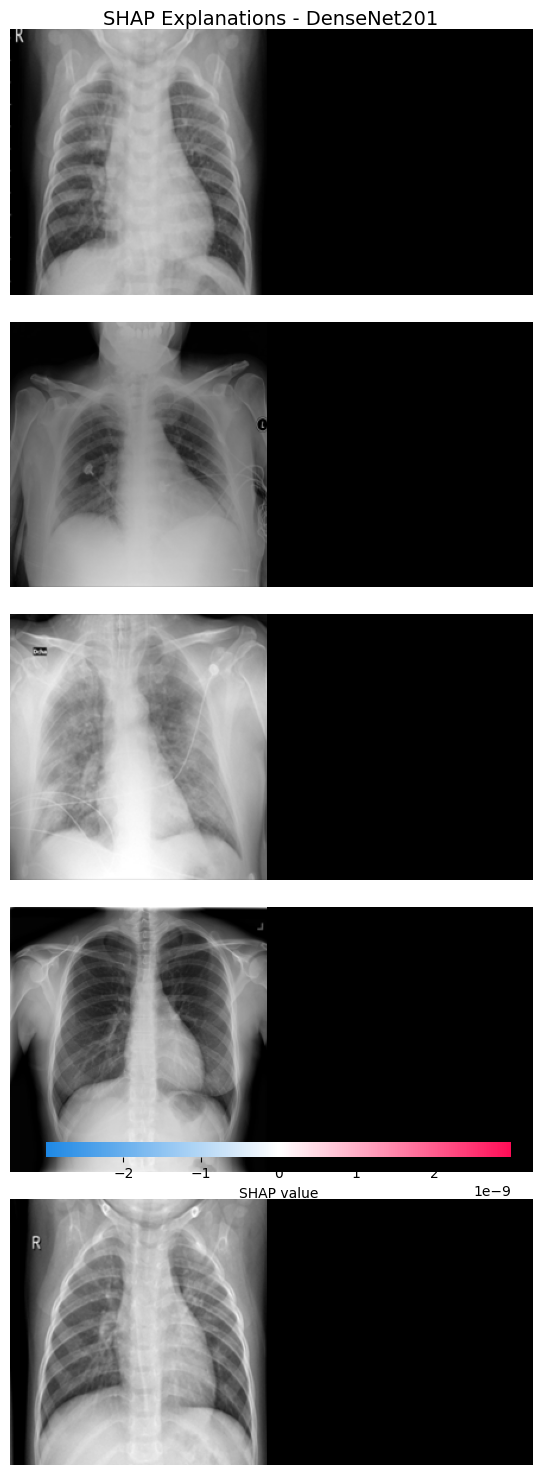

Generating SHAP plots for InceptionResNetV2...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_721
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_721
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


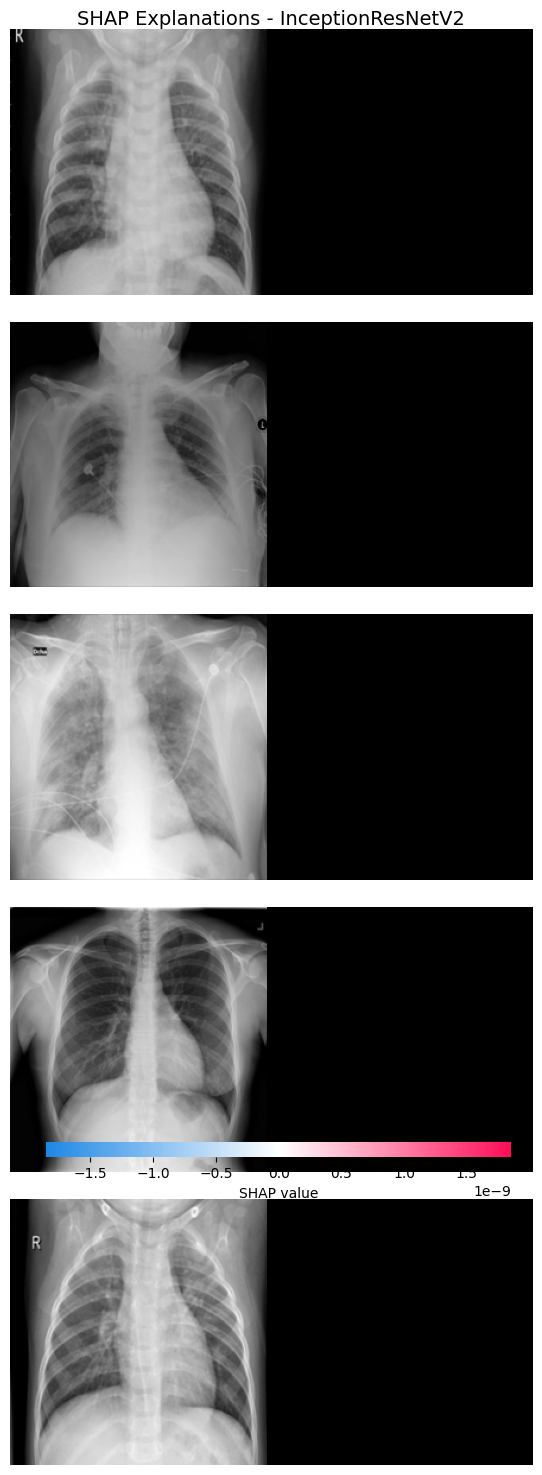

Generating SHAP plots for Xception...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1515
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1515
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


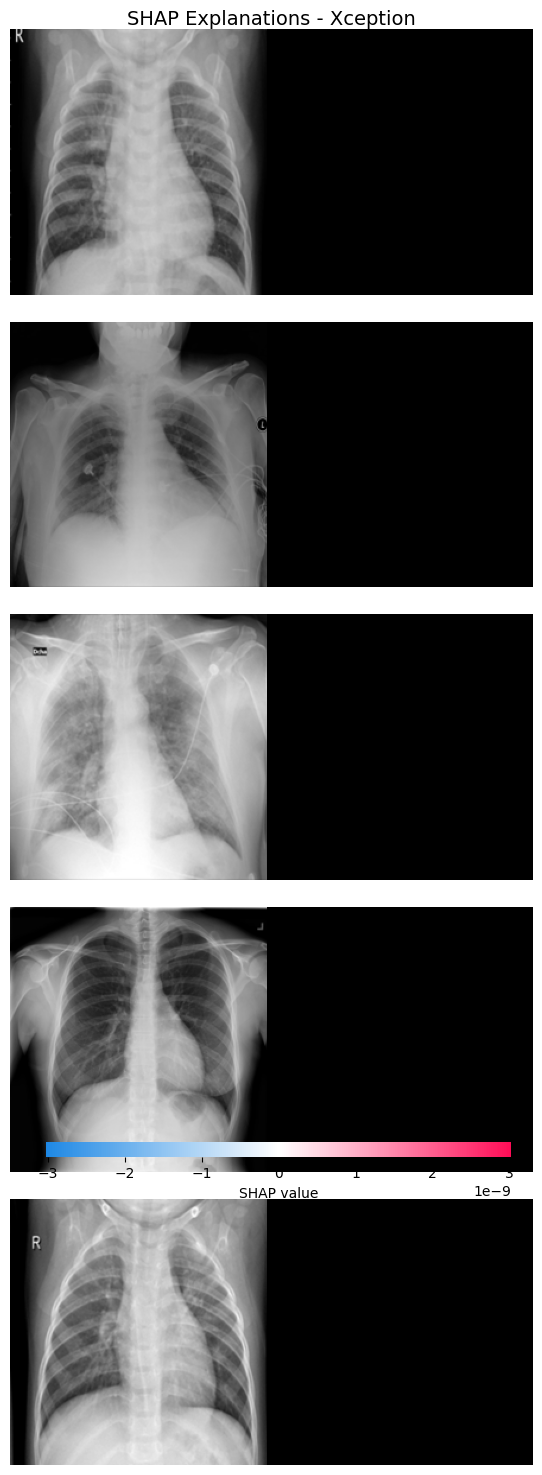

Generating SHAP plots for VGG16...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1661
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1661
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


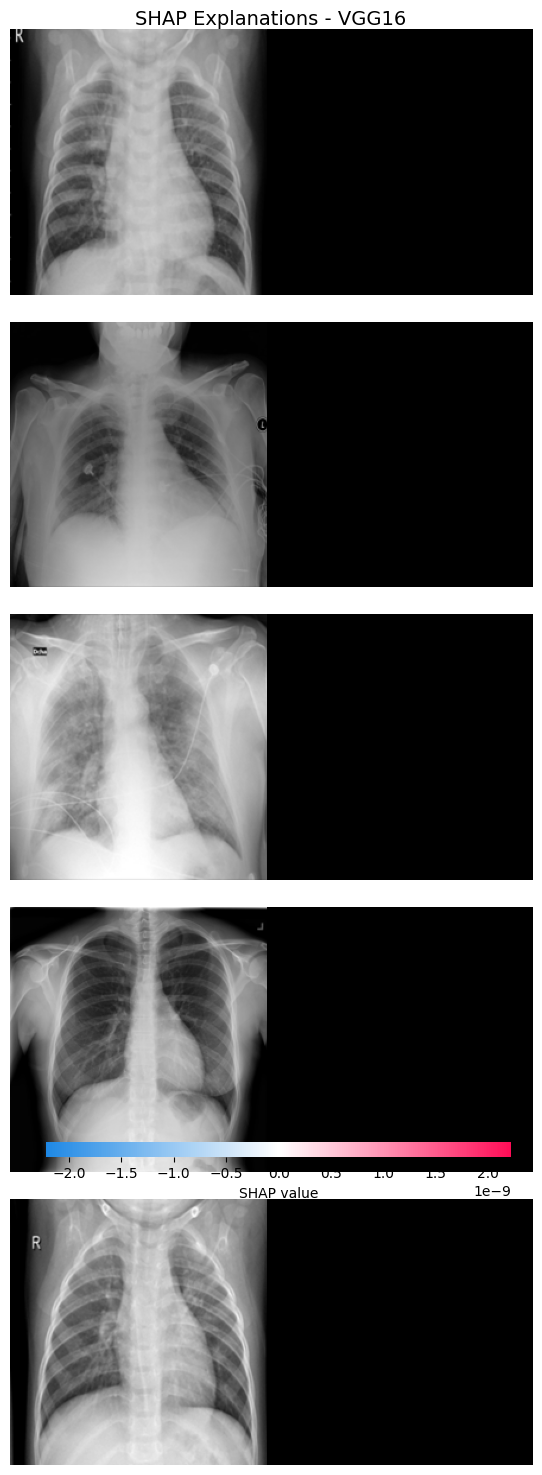

Generating SHAP plots for ResNet50...


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1694
Received: inputs=['Tensor(shape=(5, 224, 224, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1694
Received: inputs=['Tensor(shape=(50, 224, 224, 3))']
  warnings.warn(msg)


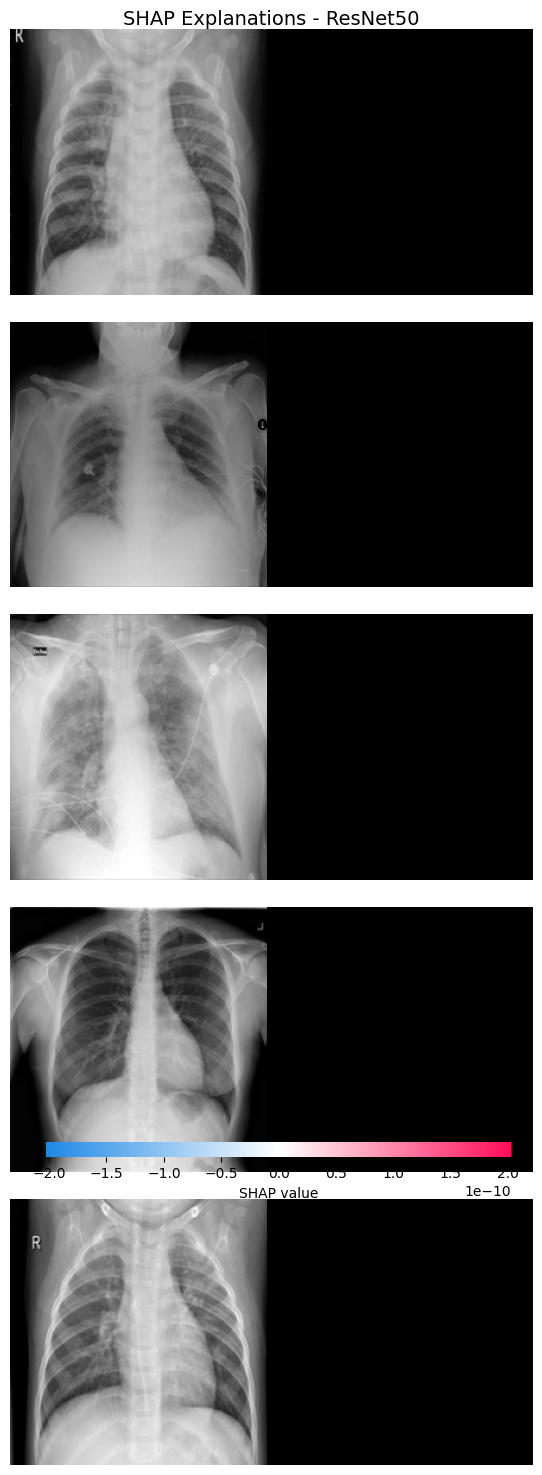

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Helper function to load and preprocess images for TensorFlow
def load_tf_image(path):
    img = Image.open(path).convert("RGB").resize((224, 224))
    img_array = np.array(img, dtype=np.float32)
    img_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
    return img_preprocessed

# Sample background images from train_df and test images from test_df
background = np.stack([load_tf_image(p) for p in train_df['Filepath'].iloc[:50]])
test_batch = np.stack([load_tf_image(p) for p in test_df['Filepath'].iloc[:5]])

# Run SHAP GradientExplainer on your trained Keras models
for name, data in models.items():
    print(f"Generating SHAP plots for {name}...")
    m = data['model']

    # Initialize GradientExplainer with the Keras model and background data
    explainer = shap.GradientExplainer(m, background)
    shap_values = explainer.shap_values(test_batch)

    # Rescale test images back from [-1, 1] to [0, 1] for visualization
    display_images = (test_batch + 1.0) / 2.0
    display_images = np.clip(display_images, 0.0, 1.0)

    # Plot and save
    shap.image_plot(shap_values, display_images, show=False)
    plt.suptitle(f"SHAP Explanations - {name}", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"shap_{name}.png", bbox_inches='tight')
    plt.show()

In [ ]:
# Install required packages
!pip install -q lime scikit-image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
!pip install lime

Generating LIME explanation for DenseNet201...


  0%|          | 0/200 [00:00<?, ?it/s]

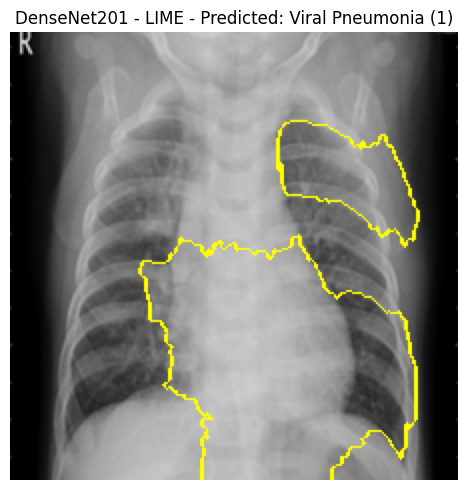

Generating LIME explanation for InceptionResNetV2...


  0%|          | 0/200 [00:00<?, ?it/s]

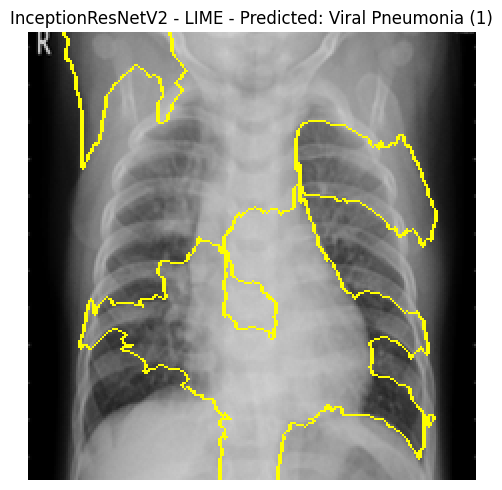

Generating LIME explanation for Xception...


  0%|          | 0/200 [00:00<?, ?it/s]

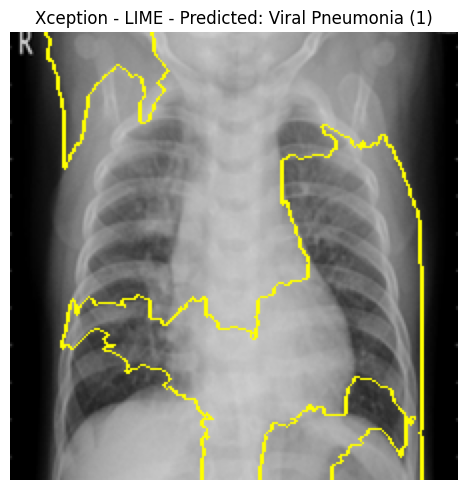

Generating LIME explanation for VGG16...


  0%|          | 0/200 [00:00<?, ?it/s]

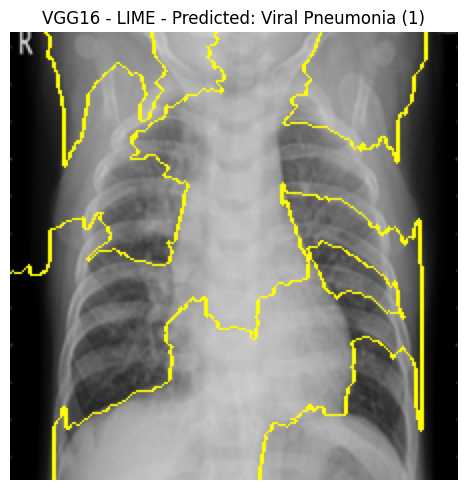

Generating LIME explanation for ResNet50...


  0%|          | 0/200 [00:00<?, ?it/s]

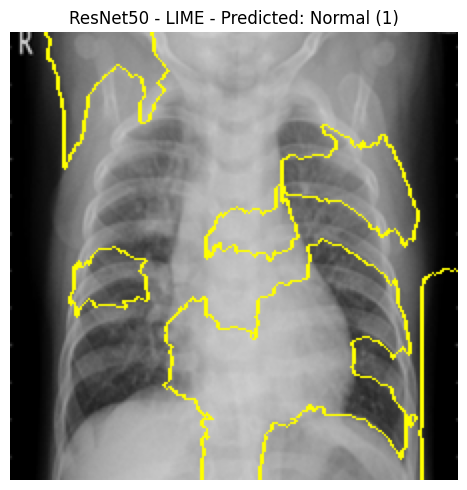

In [ ]:
# Explainable AI: LIME (superpixel perturbation on raw images)
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from lime import lime_image
from skimage.segmentation import mark_boundaries

# 1. Define the prediction wrapper function for Keras
def make_classifier_fn(model):
    def classifier_fn(images):
        # LIME perturbs images as np.ndarray (float/uint8).
        # Apply the exact MobileNetV2 preprocessing used during training.
        processed_images = np.array([
            tf.keras.applications.mobilenet_v2.preprocess_input(img.astype(np.float32))
            for img in images
        ])
        preds = model.predict(processed_images, verbose=0)
        return preds
    return classifier_fn

# 2. Get class mapping from the generator
idx_to_label = {v: k for k, v in train_images.class_indices.items()}

# 3. Initialize the LIME Image Explainer
lime_explainer = lime_image.LimeImageExplainer()

# 4. Load a sample image from test_df
img_path = test_df['Filepath'].iloc[0]
raw_img = np.array(Image.open(img_path).convert("RGB").resize((224, 224)))

# 5. Run LIME explanation across all trained models
for name, data in models.items():
    print(f"Generating LIME explanation for {name}...")
    m = data['model']
    predict_fn = make_classifier_fn(m)

    explanation = lime_explainer.explain_instance(
        image=raw_img,
        classifier_fn=predict_fn,
        top_labels=1,
        hide_color=0,
        num_samples=200,
        random_seed=42
    )

    top_label_idx = explanation.top_labels[0]
    predicted_label = idx_to_label[top_label_idx]

    temp, mask = explanation.get_image_and_mask(
        label=top_label_idx,
        positive_only=True,
        num_features=8,
        hide_rest=False
    )

    # Plot and save
    plt.figure(figsize=(5, 5))
    plt.imshow(mark_boundaries(temp.astype(np.uint8), mask))
    plt.title(f"{name} - LIME - Predicted: {predicted_label}")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"lime_{name}.png", bbox_inches='tight')
    plt.show()

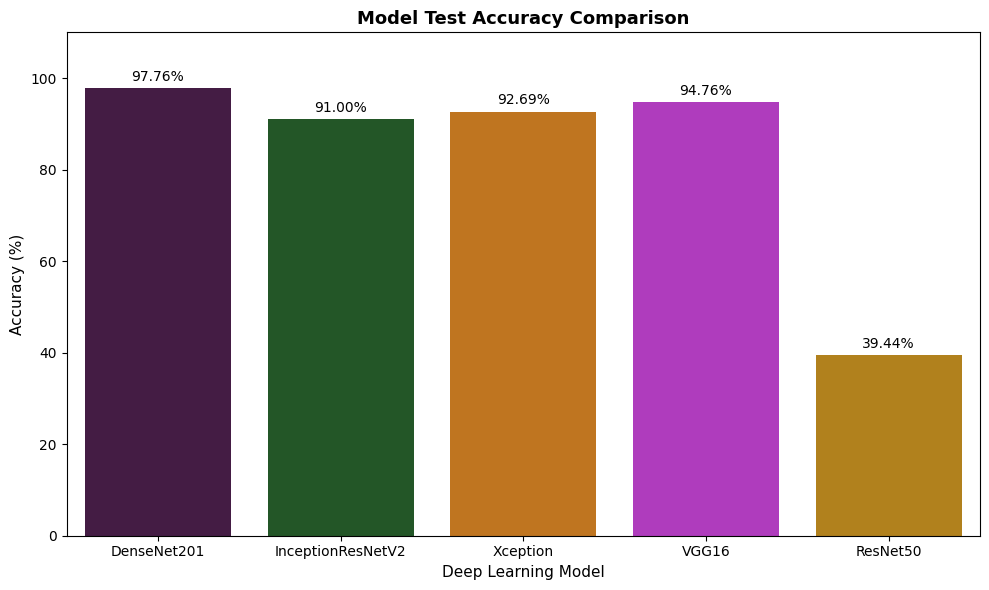

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 5 distinct colors matching the 5 models
colors = ["#4A154B", "#1B5E20", "#D97706", "#C026D3", "#CA8A04"]

# Updated with the exact test set accuracies from your output log:
# DenseNet201: 97.76%, InceptionResNetV2: 91.00%, Xception: 92.69%, VGG16: 94.76%, ResNet50: 39.44%
df = pd.DataFrame({
    'Deep Learning Model': ['DenseNet201', 'InceptionResNetV2', 'Xception', 'VGG16', 'ResNet50'],
    'Accuracy': [97.76, 91.00, 92.69, 94.76, 39.44]
})

plt.figure(figsize=(10, 6))

# Assign hue='Deep Learning Model' and legend=False to fix Seaborn deprecation warning
p = sns.barplot(
    data=df,
    x='Deep Learning Model',
    y='Accuracy',
    hue='Deep Learning Model',
    palette=colors,
    legend=False
)

# Add data labels with percentage formatting and slight padding
for container in p.containers:
    labels = [f'{v.get_height():.2f}%' for v in container]
    p.bar_label(container, labels=labels, padding=3, fontsize=10)

plt.ylim(0, 110)
plt.ylabel("Accuracy (%)", fontsize=11)
plt.xlabel("Deep Learning Model", fontsize=11)
plt.title("Model Test Accuracy Comparison", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()